# Micro proyecto 3: Generación condicional de código con LLMs

**Universidad de los Andes** · Maestría en Inteligencia Artificial (MAIA)<br>
**Curso:** Modelos Avanzados para el Procesamiento de Lenguaje Natural<br>
**Equipo:** MP1 Equipo 21

| Integrantes |
|---|
| Juan Javier Valera Mejías |
| Juan David Villalba Guavita |
| Juan Felipe Rodríguez Granados |
| Leidy Dayana Vega Medina |
| Cesar Steven Leal Pérez |

## 1. Portada e introducción

El objetivo es especializar dos modelos de lenguaje de propósito general en una tarea de **generación condicional de código**: a partir de una instrucción en lenguaje natural, el modelo debe escribir una función en Python que la resuelva. Usamos el dataset **MBPP** (*Mostly Basic Python Problems*) y medimos el desempeño con **pass@1**, el porcentaje de problemas del split `test` (500) cuya solución generada pasa todos sus `assert`.

Se comparan cuatro configuraciones:

| # | Modelo | Versión | Entrenamiento |
|---|---|---|---|
| 1 | Qwen2.5-1.5B | Original (zero-shot) | Ninguno |
| 2 | Qwen2.5-1.5B | Finetuned | LoRA sobre MBPP `train` |
| 3 | SmolLM2-1.7B | Original (zero-shot) | Ninguno |
| 4 | SmolLM2-1.7B | Finetuned | LoRA sobre MBPP `train` |

Resumen de las decisiones de diseño:

- **Prompt**: instrucción del problema más sus casos de prueba (así el modelo conoce el nombre y la firma de la función), y la solución se abre con un bloque ```` ```python ````. El mismo formato sirve para los modelos base, que cierran el bloque de forma natural, y para el finetuning, donde el objetivo es el código de referencia seguido del cierre del bloque y el `eos`.
- **Finetuning**: LoRA sobre las proyecciones de atención (`q/k/v/o_proj`), con un bucle de entrenamiento propio en PyTorch (AdamW, warmup y decaimiento coseno, acumulación de gradiente, precisión mixta). Los tokens del prompt tienen label `-100`, así que la pérdida solo cuenta el código.
- **Seguimiento y selección**: al final de cada época se mide la pérdida y el **pass@1 sobre `validation`**. Se guarda el adaptador de la época con mejor pass@1 en validación, no el de la última época, para no quedarnos con un modelo sobreajustado.
- **Evaluación**: generación por lotes (padding a la izquierda, `attention_mask`, recorte del prompt), decodificación greedy, los mismos `max_new_tokens` y criterios de parada para las cuatro configuraciones, y ejecución de los `assert` en un subproceso aislado con tiempo límite.

## 2. Librerías

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('peft') is None:  # en Colab peft no siempre viene instalado
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'peft'], check=True)
# Colab trae torchao 0.10 y peft exige >= 0.16 aunque no se use: se desinstala (no hace falta)
if importlib.util.find_spec('torchao') is not None:
    subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-q', '-y', 'torchao'], check=True)
import os
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')  # menos fragmentación en la GPU

'expandable_segments:True'

In [2]:
import os, re, gc, ast, json, math, time, random, shutil, tempfile, contextlib
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import datasets
import transformers
import peft
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, get_cosine_schedule_with_warmup
from peft import LoraConfig, PeftModel, get_peft_model
from IPython.display import display, Markdown

transformers.logging.set_verbosity_error()
datasets.logging.set_verbosity_error()

print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | transformers {transformers.__version__} '
      f'| peft {peft.__version__} | datasets {datasets.__version__}')

Python 3.13.16 | torch 2.14.1+cu130 | transformers 5.22.1 | peft 0.21.2 | datasets 4.8.5


In [3]:
SEMILLA = 21
MODELOS = {'Qwen2.5-1.5B': 'Qwen/Qwen2.5-1.5B', 'SmolLM2-1.7B': 'HuggingFaceTB/SmolLM2-1.7B'}

# Generación: idéntica para las cuatro configuraciones
MAX_LEN_PROMPT = 512        # los prompts de MBPP no pasan de ~400 tokens, no se trunca nada
MAX_NEW_TOKENS = 320        # el código de referencia más largo de test cabe holgado (ver sección 3)
BATCH_GEN = 16
STOP = ['```']              # el bloque de código se cierra -> fin de la solución
TIMEOUT_TESTS = 20          # segundos por problema (la referencia más lenta de test tarda ~10 s en Colab)

# Finetuning con LoRA
MAX_LEN_TRAIN = 768
LORA = dict(r=16, lora_alpha=32, lora_dropout=0.05,
            target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj'], task_type='CAUSAL_LM')
HP = {
    'Qwen2.5-1.5B': dict(lr=1e-4, epocas=3),
    'SmolLM2-1.7B': dict(lr=2e-4, epocas=4),
}
MICRO_BATCH, ACCUM = 4, 4   # batch efectivo de 16 ejemplos -> ~24 pasos de optimización por época
WARMUP, WEIGHT_DECAY, CLIP = 0.1, 0.0, 1.0

MODO_PRUEBA = os.environ.get('MP3_PRUEBA') == '1'  # solo para depurar el código en CPU con modelos pequeños
if MODO_PRUEBA:
    MODELOS = {'Qwen2.5-1.5B': 'Qwen/Qwen2.5-0.5B', 'SmolLM2-1.7B': 'HuggingFaceTB/SmolLM2-135M'}
    MAX_NEW_TOKENS, BATCH_GEN, MICRO_BATCH, ACCUM = 96, 4, 2, 2
    HP = {k: dict(lr=2e-4, epocas=1) for k in MODELOS}

In [4]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    # La T4 no soporta bf16: ahí los pesos van en fp16 y se entrena con GradScaler
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    props = torch.cuda.get_device_properties(0)
    print(f'GPU: {props.name} ({props.total_memory / 2**30:.1f} GB) | pesos y autocast en {DTYPE}')
else:
    DTYPE = torch.float32
    print('Sin GPU: se usa CPU en float32 (solo sirve para depurar)')


def autocast():
    return torch.autocast('cuda', dtype=DTYPE) if DEVICE == 'cuda' else contextlib.nullcontext()


EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DIR_BASE = '/content/drive/MyDrive/MP3_Equipo21'
else:
    DIR_BASE = os.environ.get('MP3_DIR', './mp3_salida')
DIR_ADAPTERS = os.path.join(DIR_BASE, 'adapters')
DIR_RESULTADOS = os.path.join(DIR_BASE, 'resultados')
os.makedirs(DIR_ADAPTERS, exist_ok=True)
os.makedirs(DIR_RESULTADOS, exist_ok=True)
CLAVE = {'Qwen2.5-1.5B': 'qwen2.5-1.5b', 'SmolLM2-1.7B': 'smollm2-1.7b'}
RUTAS_ADAPTER = {k: os.path.join(DIR_ADAPTERS, f'{CLAVE[k]}-lora') for k in MODELOS}
# Si los adaptadores y resultados ya existen en la carpeta se cargan en vez de recalcularse
# (útil si se cae la sesión de Colab). Con True se entrena y evalúa todo de nuevo.
RECALCULAR = False


def fijar_semillas(semilla=SEMILLA):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)


def liberar_memoria():
    gc.collect()
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()


def cargar_tokenizador(nombre):
    tok = AutoTokenizer.from_pretrained(MODELOS[nombre])
    if tok.pad_token is None:      # SmolLM2 no trae token de relleno
        tok.pad_token = tok.eos_token
    return tok


def cargar_modelo(nombre, tok):
    model = AutoModelForCausalLM.from_pretrained(MODELOS[nombre], dtype=DTYPE).to(DEVICE)
    model.config.pad_token_id = tok.pad_token_id
    model.generation_config.pad_token_id = tok.pad_token_id
    return model


fijar_semillas()
print('Carpeta de salida:', DIR_BASE)

GPU: Tesla T4 (14.6 GB) | pesos y autocast en torch.float16
Mounted at /content/drive
Carpeta de salida: /content/drive/MyDrive/MP3_Equipo21


## 3. Carga del dataset y exploración

Usamos la configuración `full` de MBPP. Cada ejemplo trae la instrucción (`text`), la solución de referencia (`code`), la lista de `assert` (`test_list`), código de preparación opcional (`test_setup_code`) y pruebas adicionales (`challenge_test_list`, vacías en casi todos los problemas).

In [5]:
ds = load_dataset('google-research-datasets/mbpp', 'full')
print(ds)

filas = []
for split in ds:
    d = ds[split]
    filas.append({'split': split, 'problemas': len(d),
                  'task_id': f"{min(d['task_id'])}-{max(d['task_id'])}",
                  'asserts por problema': round(np.mean([len(t) for t in d['test_list']]), 2),
                  'con test_setup_code': sum(bool(s.strip()) for s in d['test_setup_code']),
                  'con challenge_test_list': sum(bool(c) for c in d['challenge_test_list'])})
display(pd.DataFrame(filas).set_index('split'))

README.md:   0%|          | 0.00/9.06k [00:00<?, ?B/s]

full/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 87.2kB            

full/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

full/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  116kB            

full/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

full/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 25.1kB            

... (5 outputs left out)

Generating validation split:   0%|          | 0/90 [00:00<?, ? examples/s]

Generating prompt split:   0%|          | 0/10 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['task_id', 'text', 'code', 'test_list', 'test_setup_code', 'challenge_test_list'],
        num_rows: 374
    })
    test: Dataset({
        features: ['task_id', 'text', 'code', 'test_list', 'test_setup_code', 'challenge_test_list'],
        num_rows: 500
    })
    validation: Dataset({
        features: ['task_id', 'text', 'code', 'test_list', 'test_setup_code', 'challenge_test_list'],
        num_rows: 90
    })
    prompt: Dataset({
        features: ['task_id', 'text', 'code', 'test_list', 'test_setup_code', 'challenge_test_list'],
        num_rows: 10
    })
})


,problemas,task_id,asserts por problema,con test_setup_code,con challenge_test_list
split,,,,,
train,374,601-974,3.0,1,0
test,500,11-510,3.0,1,11
validation,90,511-600,3.0,0,0
prompt,10,1-10,3.0,0,0


In [6]:
ex = ds['test'][0]
print('task_id:', ex['task_id'])
print('\n--- text (instrucción) ---\n' + ex['text'])
print('\n--- code (solución de referencia) ---\n' + ex['code'])
print('\n--- test_list ---\n' + '\n'.join(ex['test_list']))

task_id: 11

--- text (instrucción) ---
Write a python function to remove first and last occurrence of a given character from the string.

--- code (solución de referencia) ---
def remove_Occ(s,ch): 
    for i in range(len(s)): 
        if (s[i] == ch): 
            s = s[0 : i] + s[i + 1:] 
            break
    for i in range(len(s) - 1,-1,-1):  
        if (s[i] == ch): 
            s = s[0 : i] + s[i + 1:] 
            break
    return s 

--- test_list ---
assert remove_Occ("hello","l") == "heo"
assert remove_Occ("abcda","a") == "bcd"
assert remove_Occ("PHP","P") == "H"


Medimos la longitud en tokens (con el tokenizador de Qwen2.5) de la instrucción y del código de referencia para fijar `MAX_NEW_TOKENS` y las longitudes máximas con datos y no a ojo.

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

mediana       p95      máximo     
campo         code text code text   code text
split                                        
test            46   15  143   24    432   47
train           43   16  146   23    289   50
validation      42   15  150   23    205   28

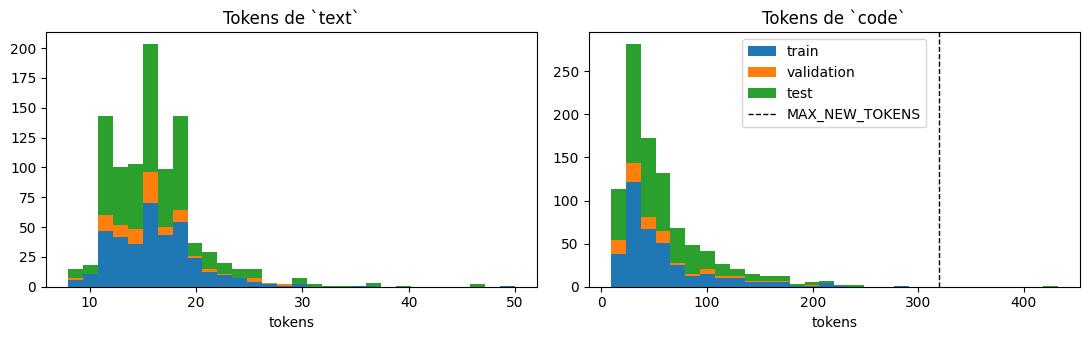

Problemas de test cuyo código de referencia supera MAX_NEW_TOKENS=320: 1


In [7]:
tok_exploracion = AutoTokenizer.from_pretrained(MODELOS['Qwen2.5-1.5B'])
largos = {split: {'text': [len(tok_exploracion(t)['input_ids']) for t in ds[split]['text']],
                  'code': [len(tok_exploracion(c)['input_ids']) for c in ds[split]['code']]}
          for split in ['train', 'validation', 'test']}

resumen = pd.DataFrame([{'split': s, 'campo': c, 'mediana': int(np.median(v)), 'p95': int(np.percentile(v, 95)),
                         'máximo': int(np.max(v))} for s, d in largos.items() for c, v in d.items()])
display(resumen.pivot(index='split', columns='campo'))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for i, campo in enumerate(['text', 'code']):
    ax[i].hist([largos[s][campo] for s in largos], bins=30, label=list(largos), stacked=True)
    ax[i].set_title(f'Tokens de `{campo}`')
    ax[i].set_xlabel('tokens')
ax[1].axvline(MAX_NEW_TOKENS, color='k', ls='--', lw=1, label='MAX_NEW_TOKENS')
ax[1].legend()
plt.tight_layout()
plt.show()

print(f"Problemas de test cuyo código de referencia supera MAX_NEW_TOKENS={MAX_NEW_TOKENS}: "
      f"{sum(n > MAX_NEW_TOKENS for n in largos['test']['code'])}")

In [8]:
# Qué tipo de problemas hay: verbos más comunes al inicio de la instrucción
verbos = Counter(re.sub(r'^write (a |an )?(python )?(function|program) to ', '', t.lower()).split()[0]
                 for t in ds['train']['text'])
print('Primeras palabras más frecuentes tras "Write a function to":',
      ', '.join(f'{v} ({n})' for v, n in verbos.most_common(12)))

Primeras palabras más frecuentes tras "Write a function to": find (120), check (54), count (30), remove (20), convert (15), calculate (13), sort (11), write (10), get (7), extract (6), add (6), replace (4)


## 4. Construcción de prompts y preprocesamiento

**Formato del prompt.** Los dos modelos son modelos base (no *instruct*), así que en lugar de una plantilla de chat usamos un formato tipo Markdown, muy común en sus datos de pre-entrenamiento: la tarea, las pruebas que debe pasar y un bloque de código abierto. Incluir las pruebas es la práctica estándar con MBPP: sin ellas el modelo no puede adivinar el nombre exacto ni la firma de la función que los `assert` llaman.

**Objetivo del finetuning.** El código de referencia, el cierre del bloque (```` ``` ````) y el token `eos`. Así el modelo aprende tanto a escribir la solución como a terminarla, y en la evaluación el cierre del bloque sirve de criterio de parada.

**Enmascaramiento.** El prompt y el objetivo se tokenizan por separado y se concatenan, de modo que la frontera entre ambos es exacta. Las posiciones del prompt reciben label `-100` y la función de costo las ignora.

In [9]:
def construir_prompt(ex):
    pruebas = '\n'.join(ex['test_list'])
    return (f"### Task\n{ex['text'].strip()}\n\n"
            f"### Your code should pass these tests\n```python\n{pruebas}\n```\n\n"
            f"### Solution\n```python\n")


def normalizar_codigo(codigo):
    return codigo.replace('\r\n', '\n').replace('\r', '\n').strip('\n')


def construir_objetivo(ex):
    return normalizar_codigo(ex['code']) + '\n```'


def preparar_ejemplo(ex, tok):
    ids_prompt = tok(construir_prompt(ex), add_special_tokens=False)['input_ids']
    ids_obj = tok(construir_objetivo(ex), add_special_tokens=False)['input_ids'] + [tok.eos_token_id]
    input_ids = (ids_prompt + ids_obj)[:MAX_LEN_TRAIN]
    labels = ([-100] * len(ids_prompt) + ids_obj)[:MAX_LEN_TRAIN]
    return {'input_ids': input_ids, 'labels': labels}


def colacionar(lote, pad_id):
    # En entrenamiento el relleno va a la derecha y nunca se usa para la pérdida (label -100)
    largo = max(len(e['input_ids']) for e in lote)
    input_ids = torch.full((len(lote), largo), pad_id, dtype=torch.long)
    labels = torch.full((len(lote), largo), -100, dtype=torch.long)
    attention_mask = torch.zeros((len(lote), largo), dtype=torch.long)
    for i, e in enumerate(lote):
        n = len(e['input_ids'])
        input_ids[i, :n] = torch.tensor(e['input_ids'])
        labels[i, :n] = torch.tensor(e['labels'])
        attention_mask[i, :n] = 1
    return {'input_ids': input_ids, 'attention_mask': attention_mask, 'labels': labels}


print(construir_prompt(ds['train'][0]) + construir_objetivo(ds['train'][0]))

### Task
Write a function to find the longest chain which can be formed from the given set of pairs.

### Your code should pass these tests
```python
assert max_chain_length([Pair(5, 24), Pair(15, 25),Pair(27, 40), Pair(50, 60)], 4) == 3
assert max_chain_length([Pair(1, 2), Pair(3, 4),Pair(5, 6), Pair(7, 8)], 4) == 4
assert max_chain_length([Pair(19, 10), Pair(11, 12),Pair(13, 14), Pair(15, 16), Pair(31, 54)], 5) == 5
```

### Solution
```python
class Pair(object): 
	def __init__(self, a, b): 
		self.a = a 
		self.b = b 
def max_chain_length(arr, n): 
	max = 0
	mcl = [1 for i in range(n)] 
	for i in range(1, n): 
		for j in range(0, i): 
			if (arr[i].a > arr[j].b and
				mcl[i] < mcl[j] + 1): 
				mcl[i] = mcl[j] + 1
	for i in range(n): 
		if (max < mcl[i]): 
			max = mcl[i] 
	return max
```


In [10]:
# Verificación del enmascaramiento con los dos tokenizadores
for nombre in MODELOS:
    tok = cargar_tokenizador(nombre)
    e = preparar_ejemplo(ds['train'][0], tok)
    n_prompt = sum(l == -100 for l in e['labels'])
    objetivo = tok.decode([t for t, l in zip(e['input_ids'], e['labels']) if l != -100])
    print(f'{nombre}: {len(e["input_ids"])} tokens, {n_prompt} enmascarados con -100 (prompt), '
          f'{len(e["input_ids"]) - n_prompt} con pérdida | pad="{tok.pad_token}" eos="{tok.eos_token}"')
    assert objetivo == construir_objetivo(ds['train'][0]) + tok.eos_token
    assert tok.decode(e['input_ids'][:n_prompt]) == construir_prompt(ds['train'][0])

tok = cargar_tokenizador('SmolLM2-1.7B')
e = preparar_ejemplo(ds['train'][0], tok)
tabla = pd.DataFrame({'token': [repr(tok.decode([t])) for t in e['input_ids']], 'label': e['labels']})
print('\nFrontera prompt / solución (SmolLM2):')
corte = sum(l == -100 for l in e['labels'])
display(tabla.iloc[corte - 6: corte + 8].T)

Qwen2.5-1.5B: 333 tokens, 185 enmascarados con -100 (prompt), 148 con pérdida | pad="<|endoftext|>" eos="<|endoftext|>"


config.json:   0%|          | 0.00/635 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

SmolLM2-1.7B: 372 tokens, 194 enmascarados con -100 (prompt), 178 con pérdida | pad="<|endoftext|>" eos="<|endoftext|>"

Frontera prompt / solución (SmolLM2):


,188,189,190,191,192,193,194,195,196,197,198,199,200,201
token,'###',' Solution','\n','```','python','\n','class',' Pair','(','object','):',' \n','\t','def'
label,-100,-100,-100,-100,-100,-100,2064,35895,24,4743,727,3717,197,1604


## 5. Particiones (train / validation / test)

Usamos las particiones oficiales de MBPP sin mezclarlas:

| Split | Problemas | Rol |
|---|---|---|
| `train` | 374 | Finetuning con LoRA |
| `validation` | 90 | Seguimiento por época (pérdida y pass@1) y selección del mejor adaptador |
| `test` | 500 | Solo para la evaluación final del pass@1 de las cuatro configuraciones |
| `prompt` | 10 | No se usa (está pensado para ejemplos *few-shot*; aquí todo es zero-shot) |

El split `test` no se toca durante el entrenamiento ni para elegir hiperparámetros o época.

In [11]:
train_ds, val_ds, test_ds = ds['train'], ds['validation'], ds['test']
if MODO_PRUEBA:
    train_ds, val_ds, test_ds = train_ds.select(range(16)), val_ds.select(range(8)), test_ds.select(range(12))

ids = {n: set(d['task_id']) for n, d in [('train', train_ds), ('validation', val_ds), ('test', test_ds)]}
assert not (ids['train'] & ids['test']) and not (ids['validation'] & ids['test']) and not (ids['train'] & ids['validation'])
print({n: len(v) for n, v in ids.items()}, '| sin solapamiento de task_id entre particiones')

{'train': 374, 'validation': 90, 'test': 500} | sin solapamiento de task_id entre particiones


## 6. Implementación de la evaluación pass@1

**Generación por lotes** (según el anexo): padding a la izquierda para que el último token real de cada fila quede al final, `attention_mask` para ignorar el relleno, `pad_token = eos_token` cuando el modelo no trae uno, y recorte vectorizado del prompt con `out[:, input_ids.shape[1]:]`. Además, los prompts se ordenan por longitud antes de armar los lotes para reducir el relleno, y el resultado se devuelve en el orden original. La decodificación es greedy (`do_sample=False`) y la generación se detiene en el cierre del bloque de código (`stop_strings`), en `eos` o en `MAX_NEW_TOKENS`.

**Extracción del código.** Se toma el texto hasta el cierre del bloque, se descartan las líneas de nivel superior con pruebas o impresiones que algunos modelos agregan después de la función (`assert`, `print(`, `if __name__`) y, si lo que queda no compila, se recortan líneas del final hasta que compile (por ejemplo, una línea cortada por `MAX_NEW_TOKENS`). Es el mismo post-procesamiento para las cuatro configuraciones.

**Ejecución de los `assert`.** El fragmento guía del enunciado usa `exec` en el mismo proceso, pero así un bucle infinito o un `input()` del modelo bloquearían el notebook. Por eso cada solución se ejecuta en un **subproceso de Python aislado** (`-I`, directorio temporal, sin entrada estándar) con tiempo límite. Una solución es correcta solo si el proceso termina sin error, es decir, si pasan todos sus `assert`.

In [12]:
@torch.no_grad()
def generar_por_lotes(model, tok, prompts, batch_size=BATCH_GEN, max_new_tokens=MAX_NEW_TOKENS):
    tok.padding_side = 'left'
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model.config.pad_token_id = tok.pad_token_id
    model.eval()
    orden = sorted(range(len(prompts)), key=lambda i: len(prompts[i]), reverse=True)
    salidas = [None] * len(prompts)
    t0 = time.time()
    for k in range(0, len(orden), batch_size):
        idx = orden[k:k + batch_size]
        inputs = tok([prompts[i] for i in idx], return_tensors='pt', padding=True, truncation=True,
                     max_length=MAX_LEN_PROMPT, add_special_tokens=False).to(model.device)
        with autocast():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                                 temperature=None, top_p=None, top_k=None,
                                 pad_token_id=tok.pad_token_id, eos_token_id=tok.eos_token_id,
                                 stop_strings=STOP, tokenizer=tok)
        gen = out[:, inputs['input_ids'].shape[1]:]   # se recorta el prompt (con su relleno)
        for i, texto in zip(idx, tok.batch_decode(gen, skip_special_tokens=True)):
            salidas[i] = texto
        hechos = min(k + batch_size, len(orden))
        print(f'\r  generando: {hechos}/{len(orden)} prompts | {time.time() - t0:.0f} s', end='', flush=True)
    print()
    return salidas


CORTES = ('assert', 'print(', 'if __name__')


def compila(codigo):
    try:
        ast.parse(codigo)
        return True
    except (SyntaxError, ValueError):
        return False


def extraer_codigo(texto):
    texto = texto.split('```')[0]
    lineas = []
    for linea in texto.split('\n'):
        if linea[:1].strip() and linea.startswith(CORTES):
            break
        lineas.append(linea)
    codigo = '\n'.join(lineas).rstrip()
    recortado = list(lineas)
    while recortado and not compila('\n'.join(recortado)):
        recortado.pop()
    return '\n'.join(recortado).rstrip() if recortado else codigo


ENTORNO_TESTS = {k: v for k, v in os.environ.items() if k not in ('FORCE_COLOR', 'CLICOLOR_FORCE')}
ENTORNO_TESTS.update(PYTHON_COLORS='0', NO_COLOR='1')


def ejecutar_tests(codigo, test_list, setup_code='', timeout=TIMEOUT_TESTS):
    """Ejecuta la solución y sus assert en un subproceso aislado. Devuelve (pasa, tipo_de_error)."""
    # El setup va después del código: en MBPP usa clases que define la solución (p. ej. Node en la tarea 367)
    programa = f'{codigo}\n\n{setup_code}\n' + '\n'.join(test_list) + '\n'
    with tempfile.TemporaryDirectory() as carpeta:
        ruta = os.path.join(carpeta, 'solucion.py')
        with open(ruta, 'w', encoding='utf-8') as f:
            f.write(programa)
        try:
            r = subprocess.run([sys.executable, '-I', ruta], cwd=carpeta, stdin=subprocess.DEVNULL,
                               capture_output=True, text=True, timeout=timeout, env=ENTORNO_TESTS)
        except subprocess.TimeoutExpired:
            return False, 'Timeout'
    if r.returncode == 0:
        return True, None
    stderr = re.sub(r'\x1b\[[0-9;]*m', '', r.stderr)
    error = re.findall(r'^(\w+(?:Error|Exception|Exit|Interrupt))\b', stderr, flags=re.M)
    return False, error[-1] if error else 'Otro'


def ejecutar_lote(codigos, problemas):
    with ThreadPoolExecutor(max_workers=max(2, min(8, os.cpu_count() or 2))) as pool:
        return list(pool.map(lambda a: ejecutar_tests(a[0], a[1]['test_list'], a[1]['test_setup_code']),
                             zip(codigos, problemas)))


def recalificar(r, problemas):
    """Vuelve a ejecutar las pruebas sobre el código ya generado (sin volver a generar)."""
    resultados = ejecutar_lote([f['codigo'] for f in r['filas']], list(problemas))
    for f, (ok, err) in zip(r['filas'], resultados):
        f['pasa'], f['error'] = ok, err
    r['resueltos'] = sum(f['pasa'] for f in r['filas'])
    r['pass1'] = r['resueltos'] / r['n']
    return r


def evaluar_pass1(model, tok, problemas):
    problemas = list(problemas)
    t0 = time.time()
    crudas = generar_por_lotes(model, tok, [construir_prompt(p) for p in problemas])
    t_gen = time.time() - t0
    codigos = [extraer_codigo(c) for c in crudas]
    resultados = ejecutar_lote(codigos, problemas)
    filas = [{'task_id': p['task_id'], 'generacion': g, 'codigo': c, 'pasa': ok, 'error': err}
             for p, g, c, (ok, err) in zip(problemas, crudas, codigos, resultados)]
    return {'pass1': float(np.mean([f['pasa'] for f in filas])), 'resueltos': sum(f['pasa'] for f in filas),
            'n': len(filas), 'seg_generacion': round(t_gen, 1), 'seg_total': round(time.time() - t0, 1),
            'filas': filas}


def ic_wilson(k, n, z=1.96):
    p = k / n
    centro = (p + z * z / (2 * n)) / (1 + z * z / n)
    radio = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centro - radio, centro + radio

**Validación del evaluador.** Antes de evaluar los modelos comprobamos que el evaluador funciona: las soluciones de referencia deben pasar casi todas, una solución vacía no debe pasar ninguna, y un bucle infinito debe cortarse por tiempo límite.

In [13]:
t0 = time.time()
ref = ejecutar_lote([normalizar_codigo(p['code']) for p in test_ds], list(test_ds))
fallan = [(p['task_id'], err) for p, (ok, err) in zip(test_ds, ref) if not ok]
print(f'Soluciones de referencia en test: {sum(ok for ok, _ in ref)}/{len(ref)} pasan '
      f'({time.time() - t0:.1f} s para ejecutar {len(ref)} subprocesos)')
if fallan:
    print('No pasan con su propia referencia:', fallan)

p0 = test_ds[0]
print('Solución vacía:', ejecutar_tests('def f():\n    pass', p0['test_list']))
print('Bucle infinito:', ejecutar_tests('while True:\n    pass', p0['test_list'], timeout=2))
print('Pide input():', ejecutar_tests('x = input()', p0['test_list']))

prueba_extraccion = "def suma(a, b):\n    return a + b\n\nassert suma(1, 2) == 3\nprint(suma(2, 2))\n```\nTexto extra"
print('\nExtracción de código sobre una salida con pruebas y texto extra:\n' + extraer_codigo(prueba_extraccion))

Soluciones de referencia en test: 500/500 pasan (29.1 s para ejecutar 500 subprocesos)
Solución vacía: (False, 'NameError')
Bucle infinito: (False, 'Timeout')
Pide input(): (False, 'EOFError')

Extracción de código sobre una salida con pruebas y texto extra:
def suma(a, b):
    return a + b


## 7. Evaluación de los modelos base (zero-shot)

Cada modelo se carga, se evalúa sobre los 500 problemas de `test` y se libera de la GPU antes de pasar al siguiente. Los resultados (incluido el texto generado para cada problema) se guardan en JSON. Si ya existen, se carga el código generado y se vuelven a ejecutar sus pruebas, así la calificación siempre corresponde a la versión actual del evaluador.

In [14]:
def ruta_resultado(nombre, version):
    return os.path.join(DIR_RESULTADOS, f'{CLAVE[nombre]}_{version}.json')


def guardar_json(obj, ruta):
    with open(ruta, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=1)


def leer_json(ruta):
    with open(ruta, encoding='utf-8') as f:
        return json.load(f)


def resumen_eval(nombre, version, r):
    lo, hi = ic_wilson(r['resueltos'], r['n'])
    errores = Counter(f['error'] for f in r['filas'] if not f['pasa'])
    print(f"{nombre} {version}: pass@1 = {r['pass1']:.1%} ({r['resueltos']}/{r['n']}), IC95% [{lo:.1%}, {hi:.1%}] "
          f"| generación {r['seg_generacion']:.0f} s | errores: {dict(errores.most_common(4))}")


RESULTADOS = {}
for nombre in MODELOS:
    ruta = ruta_resultado(nombre, 'base')
    if os.path.exists(ruta) and not RECALCULAR:
        RESULTADOS[(nombre, 'base')] = recalificar(leer_json(ruta), test_ds)
        guardar_json(RESULTADOS[(nombre, 'base')], ruta)
    else:
        tok = cargar_tokenizador(nombre)
        model = cargar_modelo(nombre, tok)
        print(f'{nombre}: {sum(p.numel() for p in model.parameters()) / 1e9:.2f} B parámetros')
        RESULTADOS[(nombre, 'base')] = evaluar_pass1(model, tok, test_ds)
        guardar_json(RESULTADOS[(nombre, 'base')], ruta)
        del model
        liberar_memoria()
    resumen_eval(nombre, 'base', RESULTADOS[(nombre, 'base')])

Qwen2.5-1.5B base: pass@1 = 44.6% (223/500), IC95% [40.3%, 49.0%] | generación 302 s | errores: {'AssertionError': 228, 'TypeError': 22, 'NameError': 11, 'IndexError': 5}
SmolLM2-1.7B base: pass@1 = 33.8% (169/500), IC95% [29.8%, 38.1%] | generación 330 s | errores: {'AssertionError': 237, 'NameError': 42, 'TypeError': 35, 'IndexError': 6}


In [15]:
for nombre in MODELOS:
    f = RESULTADOS[(nombre, 'base')]['filas'][1]
    print(f'===== {nombre} base | task {f["task_id"]} | pasa: {f["pasa"]} =====')
    print(f['generacion'][:600])
    print()

===== Qwen2.5-1.5B base | task 12 | pasa: True =====
def sort_matrix(matrix):
    return sorted(matrix, key=sum)
```

===== SmolLM2-1.7B base | task 12 | pasa: True =====
def sort_matrix(matrix):
    return sorted(matrix, key=lambda row: sum(row))
```



## 8. Finetuning con LoRA

**Configuración de LoRA.** Rango `r=16` con `lora_alpha=32` (factor de escala 2) y `dropout=0.05` sobre las cuatro proyecciones de atención, que existen con los mismos nombres en Qwen2 y en Llama (la arquitectura de SmolLM2). Con 374 ejemplos de entrenamiento conviene un adaptador pequeño: entrenar también las capas MLP multiplica los parámetros entrenables y el riesgo de sobreajuste sin que haga falta más capacidad para aprender un formato de salida y un estilo de código.

**Bucle de entrenamiento.** AdamW sobre los parámetros del adaptador, 10 % de warmup y decaimiento coseno, recorte de gradiente a 1,0, micro-lotes de 4 con acumulación de 4 (batch efectivo 16) y precisión mixta (fp16 con `GradScaler` en la T4, bf16 en GPUs que lo soportan). El modelo base queda congelado en media precisión y el adaptador se entrena en fp32.

**Hiperparámetros.** Qwen2.5 ya es bueno en código desde el pre-entrenamiento (en su corpus hay mucho código), así que usamos una tasa de aprendizaje menor (1e-4) y 3 épocas, para ajustar el formato sin borrar lo que ya sabe. SmolLM2 parte de mucho más abajo y necesita moverse más: 2e-4 y 4 épocas.

**Seguimiento y selección.** Se registra la pérdida de entrenamiento en cada paso y, al final de cada época, la pérdida en validación y el **pass@1 en validación** (90 problemas, generados con exactamente la misma configuración que la evaluación final). También se mide la época 0, el modelo base. Se guarda el adaptador de la época con mejor pass@1 en validación (en empate, la de menor pérdida). Usamos pass@1 y no solo la pérdida porque la pérdida de validación puede subir aunque el pass@1 se mantenga o mejore: el modelo se vuelve más confiado en sus tokens y la entropía cruzada castiga más los errores, aunque el código siga siendo correcto.

In [16]:
@torch.no_grad()
def perdida_validacion(model, ejemplos, pad_id, bs=2):
    # Lotes pequeños: los logits de Qwen (vocabulario de ~152k) ocupan varios GB con lotes grandes
    model.eval()
    liberar_memoria()
    suma, tokens = 0.0, 0
    for k in range(0, len(ejemplos), bs):
        lote = {n: t.to(DEVICE) for n, t in colacionar(ejemplos[k:k + bs], pad_id).items()}
        with autocast():
            perdida = model(**lote).loss.float().item()
        n = int((lote['labels'][:, 1:] != -100).sum())
        suma += perdida * n
        tokens += n
        del lote
    liberar_memoria()
    return suma / tokens


def entrenar_lora(nombre):
    hp, ruta = HP[nombre], RUTAS_ADAPTER[nombre]
    ruta_hist = os.path.join(ruta, 'historial.json')
    if os.path.exists(ruta_hist) and not RECALCULAR:
        print(f'{nombre}: se carga el adaptador ya entrenado de {ruta}')
        return leer_json(ruta_hist)

    fijar_semillas()
    tok = cargar_tokenizador(nombre)
    model = cargar_modelo(nombre, tok)
    model = get_peft_model(model, LoraConfig(**LORA))
    model.print_trainable_parameters()

    ej_train = [preparar_ejemplo(e, tok) for e in train_ds]
    ej_val = [preparar_ejemplo(e, tok) for e in val_ds]
    pasos_epoca = math.ceil(len(ej_train) / (MICRO_BATCH * ACCUM))
    pasos_totales = pasos_epoca * hp['epocas']
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=hp['lr'],
                            weight_decay=WEIGHT_DECAY)
    sched = get_cosine_schedule_with_warmup(opt, int(WARMUP * pasos_totales), pasos_totales)
    scaler = torch.amp.GradScaler('cuda', enabled=(DTYPE == torch.float16 and DEVICE == 'cuda'))

    hist = {'modelo': nombre, 'hp': hp, 'lora': {k: v for k, v in LORA.items()},
            'parametros_entrenables': sum(p.numel() for p in model.parameters() if p.requires_grad),
            'parametros_totales': sum(p.numel() for p in model.parameters()),
            'paso': [], 'train_loss': [], 'lr': [], 'epocas': []}

    def evaluar_epoca(ep, t_epoca):
        vl = perdida_validacion(model, ej_val, tok.pad_token_id)
        vp = evaluar_pass1(model, tok, val_ds)
        tok.padding_side = 'right'
        hist['epocas'].append({'epoca': ep, 'val_loss': vl, 'val_pass1': vp['pass1'], 'val_resueltos': vp['resueltos'],
                               'seg_entrenamiento': round(t_epoca, 1)})
        print(f'  época {ep}: val_loss {vl:.4f} | val pass@1 {vp["pass1"]:.1%} ({vp["resueltos"]}/{vp["n"]})'
              + (f' | {t_epoca:.0f} s de entrenamiento' if ep else ' (modelo base)'))
        return vl, vp['pass1']

    evaluar_epoca(0, 0)
    mejor, paso = None, 0
    for ep in range(1, hp['epocas'] + 1):
        model.train()
        t0 = time.time()
        orden = list(range(len(ej_train)))
        random.Random(SEMILLA + ep).shuffle(orden)
        micro = [orden[k:k + MICRO_BATCH] for k in range(0, len(orden), MICRO_BATCH)]
        acumulado = 0.0
        for j, idx in enumerate(micro):
            lote = {n: t.to(DEVICE) for n, t in colacionar([ej_train[i] for i in idx], tok.pad_token_id).items()}
            with autocast():
                perdida = model(**lote).loss
            scaler.scale(perdida / ACCUM).backward()
            acumulado += perdida.item()
            if (j + 1) % ACCUM == 0 or j == len(micro) - 1:
                n_micro = (j % ACCUM) + 1
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], CLIP)
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
                sched.step()
                paso += 1
                hist['paso'].append(paso)
                hist['train_loss'].append(acumulado / n_micro)
                hist['lr'].append(sched.get_last_lr()[0])
                acumulado = 0.0
        vl, vp = evaluar_epoca(ep, time.time() - t0)
        if mejor is None or (vp, -vl) > (mejor[1], -mejor[2]):
            mejor = (ep, vp, vl)
            model.save_pretrained(ruta)
            tok.save_pretrained(ruta)
            print(f'    -> mejor época hasta ahora, adaptador guardado')

    hist['mejor_epoca'] = mejor[0]
    hist['pasos_por_epoca'] = pasos_epoca
    guardar_json(hist, ruta_hist)
    del model, opt
    liberar_memoria()
    return hist

In [17]:
HISTORIAL = {}
nombre = 'Qwen2.5-1.5B'
t0 = time.time()
HISTORIAL[nombre] = entrenar_lora(nombre)
print(f'{nombre}: mejor época {HISTORIAL[nombre]["mejor_epoca"]} | {time.time() - t0:.0f} s')

Qwen2.5-1.5B: se carga el adaptador ya entrenado de /content/drive/MyDrive/MP3_Equipo21/adapters/qwen2.5-1.5b-lora
Qwen2.5-1.5B: mejor época 3 | 0 s


In [18]:
nombre = 'SmolLM2-1.7B'
t0 = time.time()
HISTORIAL[nombre] = entrenar_lora(nombre)
print(f'{nombre}: mejor época {HISTORIAL[nombre]["mejor_epoca"]} | {time.time() - t0:.0f} s')

SmolLM2-1.7B: se carga el adaptador ya entrenado de /content/drive/MyDrive/MP3_Equipo21/adapters/smollm2-1.7b-lora
SmolLM2-1.7B: mejor época 3 | 0 s


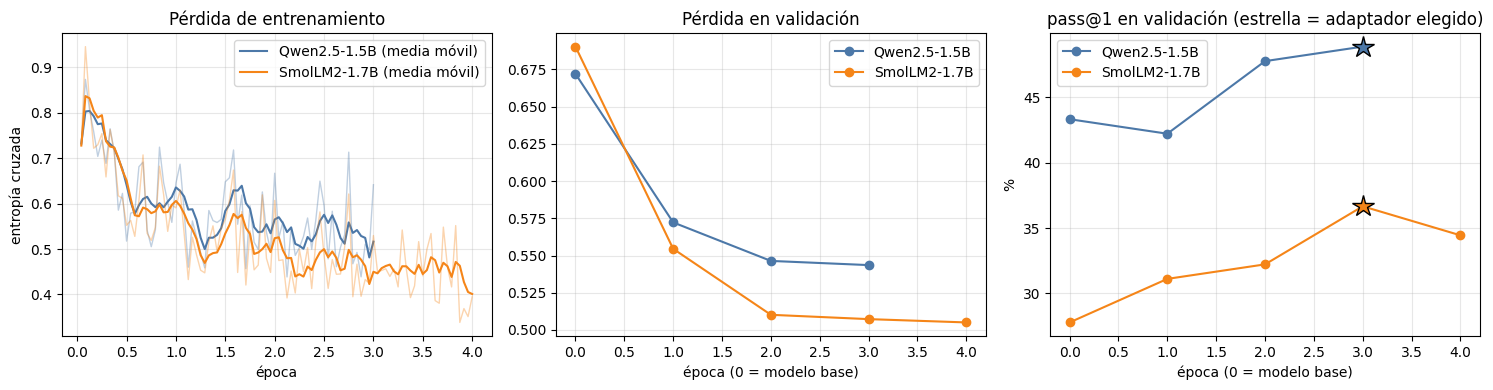

,parámetros entrenables,% del total,lr,épocas,mejor época,seg. entrenamiento
modelo,,,,,,
Qwen2.5-1.5B,"4,358,144",0.282 %,0.0001,3,3,156.5
SmolLM2-1.7B,"6,291,456",0.366 %,0.0002,4,3,253.0


val_loss  val_pass1  val_resueltos  seg_entrenamiento
modelo       epoca                                                       
Qwen2.5-1.5B 0      0.672055   0.433333             39                0.0
             1      0.572254   0.422222             38               49.1
             2      0.546390   0.477778             43               53.8
             3      0.543585   0.488889             44               53.6
SmolLM2-1.7B 0      0.690317   0.277778             25                0.0
             1      0.554513   0.311111             28               63.8
             2      0.510201   0.322222             29               62.5
             3      0.507297   0.366667             33               62.5
             4      0.505075   0.344444             31               64.2

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
colores = {'Qwen2.5-1.5B': '#4C78A8', 'SmolLM2-1.7B': '#F58518'}
for nombre, h in HISTORIAL.items():
    c = colores[nombre]
    x = np.array(h['paso']) / h['pasos_por_epoca']
    ax[0].plot(x, h['train_loss'], color=c, alpha=0.35, lw=1)
    suav = pd.Series(h['train_loss']).rolling(5, min_periods=1).mean()
    ax[0].plot(x, suav, color=c, label=f'{nombre} (media móvil)')
    ep = [e['epoca'] for e in h['epocas']]
    ax[1].plot(ep, [e['val_loss'] for e in h['epocas']], 'o-', color=c, label=nombre)
    ax[2].plot(ep, [100 * e['val_pass1'] for e in h['epocas']], 'o-', color=c, label=nombre)
    mejor = h['mejor_epoca']
    ax[2].plot([mejor], [100 * h['epocas'][mejor]['val_pass1']], marker='*', ms=16, color=c, mec='k')
ax[0].set(title='Pérdida de entrenamiento', xlabel='época', ylabel='entropía cruzada')
ax[1].set(title='Pérdida en validación', xlabel='época (0 = modelo base)')
ax[2].set(title='pass@1 en validación (estrella = adaptador elegido)', xlabel='época (0 = modelo base)', ylabel='%')
for a in ax:
    a.grid(alpha=0.3)
    a.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame([{'modelo': n, 'parámetros entrenables': f"{h['parametros_entrenables']:,}",
                       '% del total': f"{100 * h['parametros_entrenables'] / h['parametros_totales']:.3f} %",
                       'lr': h['hp']['lr'], 'épocas': h['hp']['epocas'], 'mejor época': h['mejor_epoca'],
                       'seg. entrenamiento': sum(e['seg_entrenamiento'] for e in h['epocas'])}
                      for n, h in HISTORIAL.items()]).set_index('modelo'))
display(pd.DataFrame([{'modelo': n, **e} for n, h in HISTORIAL.items() for e in h['epocas']]).set_index(['modelo', 'epoca']))

## 9. Evaluación de los modelos finetuneados

Se carga cada modelo base, se le aplica el adaptador elegido en la sección 8 y se fusiona (`merge_and_unload`) para que la generación sea tan rápida como la del modelo original. El conjunto de prueba, el prompt, `MAX_NEW_TOKENS`, los criterios de parada y la decodificación greedy son los mismos que en la sección 7.

In [20]:
for nombre in MODELOS:
    ruta = ruta_resultado(nombre, 'lora')
    if os.path.exists(ruta) and not RECALCULAR:
        RESULTADOS[(nombre, 'lora')] = recalificar(leer_json(ruta), test_ds)
        guardar_json(RESULTADOS[(nombre, 'lora')], ruta)
    else:
        tok = cargar_tokenizador(nombre)
        model = cargar_modelo(nombre, tok)
        model = PeftModel.from_pretrained(model, RUTAS_ADAPTER[nombre]).merge_and_unload()
        RESULTADOS[(nombre, 'lora')] = evaluar_pass1(model, tok, test_ds)
        guardar_json(RESULTADOS[(nombre, 'lora')], ruta)
        del model
        liberar_memoria()
    resumen_eval(nombre, 'LoRA', RESULTADOS[(nombre, 'lora')])

Qwen2.5-1.5B LoRA: pass@1 = 46.4% (232/500), IC95% [42.1%, 50.8%] | generación 262 s | errores: {'AssertionError': 231, 'TypeError': 16, 'IndexError': 8, 'NameError': 5}
SmolLM2-1.7B LoRA: pass@1 = 37.2% (186/500), IC95% [33.1%, 41.5%] | generación 301 s | errores: {'AssertionError': 261, 'TypeError': 30, 'NameError': 9, 'IndexError': 7}


## 10. Comparación y resultados

Además del pass@1 con su intervalo de confianza de Wilson, comparamos cada modelo base con su versión finetuned usando la **prueba de McNemar** (exacta): como las dos versiones se evalúan sobre los mismos 500 problemas, lo que importa son los problemas que cambian de resultado (los que el finetuning arregla frente a los que rompe), y no solo la diferencia entre los totales.

In [21]:
def mcnemar_exacto(b, c):
    n = b + c
    if n == 0:
        return 1.0
    cola = sum(math.comb(n, i) for i in range(0, min(b, c) + 1)) / 2 ** n
    return min(1.0, 2 * cola)


def vector(nombre, version):
    return np.array([f['pasa'] for f in RESULTADOS[(nombre, version)]['filas']])


tabla = []
for nombre in MODELOS:
    for version, etiqueta in [('base', 'Original (zero-shot)'), ('lora', 'Finetuned (LoRA)')]:
        r = RESULTADOS[(nombre, version)]
        lo, hi = ic_wilson(r['resueltos'], r['n'])
        fila = {'Modelo': nombre, 'Versión': etiqueta, 'pass@1': f"{r['pass1']:.1%}", 'IC 95 %': f'[{lo:.1%}, {hi:.1%}]',
                'Resueltos': f"{r['resueltos']}/{r['n']}", 'Δ vs. base (pp)': '', 'Arregla / rompe': '', 'p McNemar': ''}
        if version == 'lora':
            b, l = vector(nombre, 'base'), vector(nombre, 'lora')
            arregla, rompe = int((~b & l).sum()), int((b & ~l).sum())
            fila['Δ vs. base (pp)'] = f"{100 * (r['pass1'] - RESULTADOS[(nombre, 'base')]['pass1']):+.1f}"
            fila['Arregla / rompe'] = f'{arregla} / {rompe}'
            fila['p McNemar'] = f'{mcnemar_exacto(arregla, rompe):.2g}'
        tabla.append(fila)
TABLA = pd.DataFrame(tabla).set_index(['Modelo', 'Versión'])
display(TABLA)

pass@1         IC 95 % Resueltos  \
Modelo       Versión                                                 
Qwen2.5-1.5B Original (zero-shot)  44.6%  [40.3%, 49.0%]   223/500   
             Finetuned (LoRA)      46.4%  [42.1%, 50.8%]   232/500   
SmolLM2-1.7B Original (zero-shot)  33.8%  [29.8%, 38.1%]   169/500   
             Finetuned (LoRA)      37.2%  [33.1%, 41.5%]   186/500   

                                  Δ vs. base (pp) Arregla / rompe p McNemar  
Modelo       Versión                                                         
Qwen2.5-1.5B Original (zero-shot)                                            
             Finetuned (LoRA)                +1.8         41 / 32      0.35  
SmolLM2-1.7B Original (zero-shot)                                            
             Finetuned (LoRA)                +3.4         67 / 50      0.14

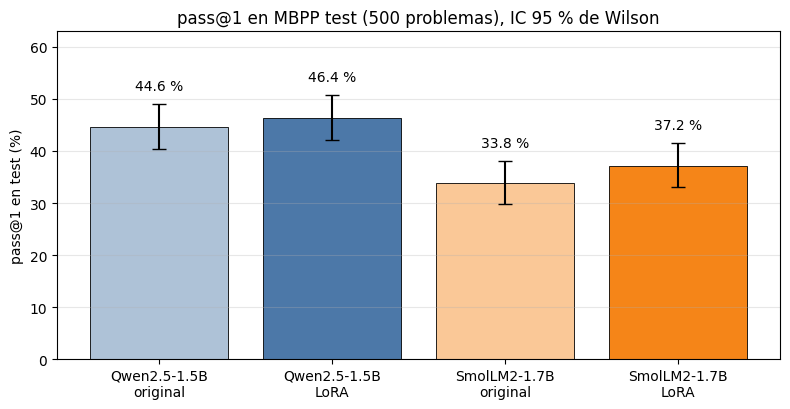

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.2))
etiquetas, valores, errs, cols = [], [], [], []
for nombre in MODELOS:
    for version, sufijo, alpha in [('base', 'original', 0.45), ('lora', 'LoRA', 1.0)]:
        r = RESULTADOS[(nombre, version)]
        lo, hi = ic_wilson(r['resueltos'], r['n'])
        etiquetas.append(f'{nombre}\n{sufijo}')
        valores.append(100 * r['pass1'])
        errs.append([100 * (r['pass1'] - lo), 100 * (hi - r['pass1'])])
        cols.append((*plt.matplotlib.colors.to_rgb(colores[nombre]), alpha))
barras = ax.bar(etiquetas, valores, yerr=np.array(errs).T, capsize=5, color=cols, edgecolor='k', lw=0.6)
ax.bar_label(barras, labels=[f'{v:.1f} %' for v in valores], padding=8)
ax.set_ylabel('pass@1 en test (%)')
ax.set_title('pass@1 en MBPP test (500 problemas), IC 95 % de Wilson')
ax.set_ylim(0, max(valores) * 1.25 + 5)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(DIR_RESULTADOS, 'pass1_comparacion.png'), dpi=150)
plt.show()

**¿En qué fallan?** Tipo de error de las soluciones que no pasan. `AssertionError` significa que el código corre pero da un resultado incorrecto; `SyntaxError`, `NameError` o `TypeError` suelen indicar código mal formado, una función con otro nombre o una firma distinta a la que esperan los `assert`.

In [23]:
errores = pd.DataFrame({f'{n} {v}': Counter(f['error'] or 'Correcto' for f in RESULTADOS[(n, v)]['filas'])
                        for n in MODELOS for v in ['base', 'lora']}).fillna(0).astype(int)
errores = errores.loc[errores.sum(axis=1).sort_values(ascending=False).index]
display(errores)

largo_codigo = pd.DataFrame({f'{n} {v}': [len(f['codigo'].splitlines()) for f in RESULTADOS[(n, v)]['filas']]
                             for n in MODELOS for v in ['base', 'lora']})
print('Líneas de código generadas por problema (mediana):', largo_codigo.median().to_dict(),
      '| referencia:', float(np.median([len(normalizar_codigo(c).splitlines()) for c in test_ds['code']])))

,Qwen2.5-1.5B base,Qwen2.5-1.5B lora,SmolLM2-1.7B base,SmolLM2-1.7B lora
AssertionError,228,231,237,261
Correcto,223,232,169,186
TypeError,22,16,35,30
NameError,11,5,42,9
IndexError,5,8,6,7
SyntaxError,4,3,3,2
ValueError,2,2,3,2
RecursionError,3,2,2,1
AttributeError,1,0,1,0
Timeout,1,1,0,0


Líneas de código generadas por problema (mediana): {'Qwen2.5-1.5B base': 2.0, 'Qwen2.5-1.5B lora': 5.0, 'SmolLM2-1.7B base': 4.0, 'SmolLM2-1.7B lora': 5.0} | referencia: 5.0


In [24]:
# Solapamiento entre los dos modelos finetuned: ¿resuelven los mismos problemas?
q, s = vector('Qwen2.5-1.5B', 'lora'), vector('SmolLM2-1.7B', 'lora')
print(f'Ambos resuelven: {int((q & s).sum())} | solo Qwen: {int((q & ~s).sum())} | solo SmolLM2: {int((~q & s).sum())} '
      f'| ninguno: {int((~q & ~s).sum())} | p McNemar Qwen vs SmolLM2 (LoRA): {mcnemar_exacto(int((q & ~s).sum()), int((~q & s).sum())):.2g}')
oraculo = np.any([vector(n, v) for n in MODELOS for v in ['base', 'lora']], axis=0)
print(f'Problemas resueltos por al menos una de las 4 configuraciones: {int(oraculo.sum())}/{len(oraculo)} ({oraculo.mean():.1%})')

Ambos resuelven: 150 | solo Qwen: 82 | solo SmolLM2: 36 | ninguno: 232 | p McNemar Qwen vs SmolLM2 (LoRA): 2.8e-05
Problemas resueltos por al menos una de las 4 configuraciones: 303/500 (60.6%)


**Ejemplos cualitativos.** Para cada modelo mostramos un problema que el finetuning arregla y, si existe, uno que rompe.

In [25]:
problemas_test = {p['task_id']: p for p in test_ds}


def mostrar_caso(nombre, task_id, titulo):
    p = problemas_test[task_id]
    fb = next(f for f in RESULTADOS[(nombre, 'base')]['filas'] if f['task_id'] == task_id)
    fl = next(f for f in RESULTADOS[(nombre, 'lora')]['filas'] if f['task_id'] == task_id)
    print(f'===== {nombre}: {titulo} (task {task_id}) =====')
    print('Tarea:', p['text'])
    print('Primer assert:', p['test_list'][0])
    for etiqueta, f in [('ORIGINAL', fb), ('LoRA', fl)]:
        print(f"\n--- {etiqueta} ({'pasa' if f['pasa'] else 'falla: ' + str(f['error'])}) ---")
        print(f['codigo'][:900] or '(vacío)')
    print()


for nombre in MODELOS:
    b, l = vector(nombre, 'base'), vector(nombre, 'lora')
    ids_test = [f['task_id'] for f in RESULTADOS[(nombre, 'base')]['filas']]
    arregla = [t for t, x, y in zip(ids_test, b, l) if not x and y]
    rompe = [t for t, x, y in zip(ids_test, b, l) if x and not y]
    if arregla:
        mostrar_caso(nombre, arregla[0], 'el finetuning lo arregla')
    if rompe:
        mostrar_caso(nombre, rompe[0], 'el finetuning lo rompe')

===== Qwen2.5-1.5B: el finetuning lo arregla (task 22) =====
Tarea: Write a function to find the first duplicate element in a given array of integers.
Primer assert: assert find_first_duplicate(([1, 2, 3, 4, 4, 5]))==4

--- ORIGINAL (falla: IndexError) ---
def find_first_duplicate(arr):
    for i in range(len(arr)):
        if arr[abs(arr[i])] >= 0:
            arr[abs(arr[i])] = -arr[abs(arr[i])]
        else:
            return abs(arr[i])
    return -1

--- LoRA (pasa) ---
def find_first_duplicate(arr):
    for i in range(len(arr)):
        if arr[abs(arr[i])-1] < 0:
            return abs(arr[i])
        arr[abs(arr[i])-1] *= -1
    return -1

===== Qwen2.5-1.5B: el finetuning lo rompe (task 33) =====
Tarea: Write a python function to convert a decimal number to binary number.
Primer assert: assert decimal_To_Binary(10) == 1010

--- ORIGINAL (pasa) ---
def decimal_To_Binary(n):
    if n == 0:
        return 0
    else:
        return n % 2 + 10 * decimal_To_Binary(n // 2)

--- LoRA

In [26]:
# Conclusión calculada a partir de los resultados de esta ejecución
pb = {n: RESULTADOS[(n, 'base')]['pass1'] for n in MODELOS}
pl = {n: RESULTADOS[(n, 'lora')]['pass1'] for n in MODELOS}
mejor_base = max(pb, key=pb.get)
mejor_lora = max(pl, key=pl.get)
lineas = [f'- **Mejor modelo original (zero-shot):** {mejor_base} con {pb[mejor_base]:.1%} '
          f'(el otro: {min(pb.values()):.1%}).',
          f'- **Mejor modelo tras el finetuning:** {mejor_lora} con {pl[mejor_lora]:.1%} '
          f'(el otro: {min(pl.values()):.1%}).']
for n in MODELOS:
    b, l = vector(n, 'base'), vector(n, 'lora')
    arregla, rompe = int((~b & l).sum()), int((b & ~l).sum())
    rel = f'{pl[n] / pb[n]:.2f}x' if pb[n] > 0 else 'n/a'
    lineas.append(f'- **Aporte del finetuning en {n}:** {100 * (pl[n] - pb[n]):+.1f} puntos ({pb[n]:.1%} → {pl[n]:.1%}, '
                  f'{rel}); arregla {arregla} problemas y rompe {rompe} (p McNemar = {mcnemar_exacto(arregla, rompe):.2g}).')
display(Markdown('\n'.join(lineas)))

- **Mejor modelo original (zero-shot):** Qwen2.5-1.5B con 44.6% (el otro: 33.8%).
- **Mejor modelo tras el finetuning:** Qwen2.5-1.5B con 46.4% (el otro: 37.2%).
- **Aporte del finetuning en Qwen2.5-1.5B:** +1.8 puntos (44.6% → 46.4%, 1.04x); arregla 41 problemas y rompe 32 (p McNemar = 0.35).
- **Aporte del finetuning en SmolLM2-1.7B:** +3.4 puntos (33.8% → 37.2%, 1.10x); arregla 67 problemas y rompe 50 (p McNemar = 0.14).

## 11. Conclusiones

**¿Cuál modelo es mejor?** Qwen2.5-1.5B, en las dos versiones. En zero-shot resuelve 44,6 % de los problemas de test frente a 33,8 % de SmolLM2-1.7B, y después del finetuning 46,4 % frente a 37,2 %. La diferencia entre los dos modelos finetuneados es significativa (McNemar p ≈ 3·10⁻⁵: 82 problemas los resuelve solo Qwen y 36 solo SmolLM2). Los dos tienen un tamaño parecido, así que la ventaja viene del pre-entrenamiento: Qwen2.5 se entrenó con una proporción grande de código y matemáticas, y SmolLM2 es un modelo más generalista. El finetuning con 374 ejemplos acorta un poco la distancia (de 10,8 a 9,2 puntos), pero no reemplaza lo que Qwen aprendió con billones de tokens de código.

**¿Cuánto aporta el finetuning?** Poco en términos absolutos: +1,8 puntos en Qwen (44,6 % → 46,4 %) y +3,4 en SmolLM2 (33,8 % → 37,2 %). Ninguna de las dos mejoras es estadísticamente significativa con 500 problemas (McNemar p = 0,35 y 0,14), porque el finetuning no suma problemas resueltos de forma limpia: los reordena. En Qwen arregla 41 y rompe 32; en SmolLM2 arregla 67 y rompe 50. La mejora es pequeña porque nuestro prompt ya resuelve en zero-shot lo que el finetuning suele enseñar en este tipo de tarea: los `assert` le dan al modelo el nombre y la firma de la función, y el bloque ```` ```python ```` hace que los dos modelos base escriban solo código y lo cierren (apenas 3 o 4 `SyntaxError` de 500 en zero-shot). Lo que el finetuning sí corrige se ve en la tabla de errores: los `NameError` (llamar una función con otro nombre o usar algo no definido) bajan de 42 a 9 en SmolLM2 y de 11 a 5 en Qwen. En SmolLM2 la mayoría de esos casos pasan a ser `AssertionError` y no aciertos: el código ya corre, pero la lógica sigue mal. Ese es el límite de lo que se puede aprender con 374 ejemplos.

**El modelo también aprende el estilo de MBPP, con sus defectos.** La mediana de líneas generadas por Qwen pasa de 2 a 5, igual que la de las soluciones de referencia: deja las soluciones compactas (`sorted(matrix, key=sum)`) y adopta el estilo más largo y procedimental del dataset. Uno de los ejemplos rotos lo muestra: después del finetuning, `decimal_To_Binary` imprime el resultado en lugar de devolverlo, un patrón que aparece en algunas referencias de MBPP. Con tan pocos datos, el modelo imita la forma de las respuestas, errores incluidos.

**Seguimiento del entrenamiento.** La pérdida de validación bajó de forma monótona en los dos modelos (Qwen 0,672 → 0,544; SmolLM2 0,690 → 0,505), pero el pass@1 de validación no la siguió. En Qwen, la primera época bajó el pass@1 por debajo del modelo base (43,3 % → 42,2 %) y luego subió hasta 48,9 % en la época 3. En SmolLM2, el máximo fue en la época 3 (36,7 %) y en la 4 bajó a 34,4 % aunque la pérdida siguió mejorando. Por eso el adaptador se elige por pass@1 de validación y no por la pérdida ni por la última época: con la pérdida nos habríamos quedado con la época 4 de SmolLM2. La tasa de aprendizaje más baja para Qwen (1e-4) y el LoRA solo en atención evitaron el sobreajuste que lleva a un modelo fuerte en código a quedar peor que su versión original. Las mejoras en validación (+5,6 y +8,9 puntos) fueron mayores que en test (+1,8 y +3,4): al elegir la mejor de varias épocas sobre solo 90 problemas, la estimación de validación queda optimista. Por eso el split `test` se reservó para la medición final.

**Limitaciones.**
- pass@1 con una sola muestra greedy mide un único intento; no dice nada sobre la diversidad de soluciones (pass@k). Si se tomara la mejor de las cuatro configuraciones para cada problema, se resolverían 303 de 500 (60,6 %), lo que muestra cuánta variación hay entre modelos y versiones.
- Las pruebas van en el prompt, así que el modelo puede ajustarse a los casos concretos en vez de resolver el problema general. Es la práctica estándar con MBPP, pero con solo 3 `assert` por problema algunas soluciones incorrectas pasan: en los ejemplos cualitativos, una función de primalidad pasa las pruebas de `is_woodall` sin calcular números de Woodall.
- MBPP tiene instrucciones ambiguas y soluciones de referencia con particularidades (nombres de función que no se deducen del texto, formatos de salida poco naturales como devolver `'Found a match!'`), y parte de los errores restantes viene de ahí.
- La selección de época usa 90 problemas, con un error estándar de unos ±5 puntos en el pass@1. Con más tiempo convendría ajustar la tasa de aprendizaje, el rango y las épocas con varias semillas y con validación cruzada sobre `train` + `validation`.
- Los dos modelos son base y pequeños, así que su desempeño queda lejos del de los modelos especializados en código o de los modelos instruct más grandes.

In [27]:
# Entregables: los dos adaptadores LoRA (el notebook se agrega al zip a mano)
zip_base = os.path.join(DIR_BASE, 'MP3_Equipo21_adaptadores')
shutil.make_archive(zip_base, 'zip', root_dir=DIR_BASE, base_dir='adapters')
print(f'{zip_base}.zip: {os.path.getsize(zip_base + ".zip") / 2**20:.1f} MB')
for nombre, ruta in RUTAS_ADAPTER.items():
    print(f'  {nombre}: {ruta} ({sorted(os.listdir(ruta))})')

/content/drive/MyDrive/MP3_Equipo21/MP3_Equipo21_adaptadores.zip: 40.2 MB
  Qwen2.5-1.5B: /content/drive/MyDrive/MP3_Equipo21/adapters/qwen2.5-1.5b-lora (['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'historial.json', 'tokenizer.json', 'tokenizer_config.json'])
  SmolLM2-1.7B: /content/drive/MyDrive/MP3_Equipo21/adapters/smollm2-1.7b-lora (['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'historial.json', 'tokenizer.json', 'tokenizer_config.json'])
